# Machine Learning - Practical 4

In [1]:
import numpy as np
import cvxopt
from matplotlib import pyplot as plt
import sklearn.tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_wine
from sklearn.tree import DecisionTreeClassifier

## Task 0: The Data

We will work with the data from Practical 3. Load the data and split it into a training and test set. You can re-use the data splitting function from Practical 2.

In [2]:
def split_data(X, y, frac=0.3, seed=None):
    if seed is not None:
        np.random.seed(seed)
        
    # ---------------- INSERT CODE ----------------------

    indices = np.random.permutation(len(X))
    X_shuffled = X[indices]
    y_shuffled = y[indices]

    # Split data
    n_test = int(len(X) * frac)

    X_train = X_shuffled[:-n_test]
    X_test = X_shuffled[-n_test:]

    y_train = y_shuffled[:-n_test]
    y_test = y_shuffled[-n_test:]

    # ---------------- END CODE -------------------------
    
    return X_train, X_test, y_train, y_test

In [3]:
# load data
X_2d, t_2d = np.load('data/nonlin_2d_data.npy')[:,:2], np.load('data/nonlin_2d_data.npy')[:, 2]

In [4]:
# split data
X_train, X_test, t_train, t_test = split_data(X_2d, t_2d, seed=1)

## Task 1: Support Vector Machines

First, you will implement a training algorithm for the Support Vector Machine (SVM). For solving the quadratic program, we provide a simple interface to the cvxopt library below.

In SVMs, each data sample $x_n$ has a corresponding lagrange multiplier $\alpha_n$ which indicates if $x_n$ is a support vector. In the latter case $\alpha_n > 0$ holds. 
The goal of learning the SVM is to figure out which samples are support vectors by learning $\mathbf{\alpha}$. The dual SVM optimizes the following quadratic program.

$$ \min \frac{1}{2} \sum_{n=1}^N \sum_{m=1}^N \alpha_n \alpha_m t_n t_m k(\mathbf{x}_n, \mathbf{x}_m) - \sum_{n=1}^N \alpha_n$$
subject to 
$$ 0 \leq \alpha_n \leq C $$
$$ \sum_{n=1}^N \alpha_n t_n = 0 $$ 

The quadratic program solver expects the following form:
$$ \min \frac{1}{2} \alpha^T P \alpha + \mathbf q^T \mathbf \alpha $$
subject to 

$$A \alpha = b$$
$$G \alpha \leq h $$

Here, $A$ and $G$ are matrices with one row per individual constraint. Similarly, $b$ (the intercept or bias) and $h$ are vectors with one element per individual constraint.

Having trained the SVM, a prediction for an input $\mathbf{x}$ is made by:

$$ y = sign([\sum_n^{N} \alpha_n t_n k(\mathbf{x}, \mathbf{x}_n)] + b)  $$


### Task 1.1
 
Use the code provided below as a basis to express the constrained optimization problem in terms of $P, q, A, b, G$ and $h$ and implement a function `fit_svm` which passes these variables to the provided QP solver. Fit a SVM on the training data and extract its parameters using a linear kernel (dot product).

**Hints:**
  - The box constraint $0 \leq \alpha_n \leq C$ defines two constraints of the form $G \alpha_n \leq h$ for each $\alpha_n$.
  - The inequality $x \geq 0$ is equivalent to $-x \leq 0$.
  - The SVM is described in chapter 12 of Elements of Statistical Learning.

In [5]:
def linear_kernel(a, b):
    # ---------------- INSERT CODE ----------------------
    
    return np.dot(a, b)

    # ---------------- END CODE -------------------------


def fit_svm(X, t, kernel, C=1.0):
    '''Fit SVM using data (X,t), specified kernel and parameter C.
    Inputs
        X:  predictors
        t:  targets
        C:  constant
    '''

    t = np.array([-1 if l == 0 else 1 for l in t])
    
    # ---------------- INSERT CODE ----------------------
    n_samples = len(X)
    K = np.array([[kernel(X[i], X[j]) for j in range(len(X))] for i in range(len(X))])
    P = np.outer(t, t) * K
    q = -np.ones(n_samples)
    A = t.reshape(1, -1).astype(float)
    b = np.array([[0.0]])
    G = np.vstack([-np.eye(n_samples), np.eye(n_samples)])
    h = np.concatenate([np.zeros(n_samples), C * np.ones(n_samples)])
    # ---------------- END CODE -------------------------
    
    assert P.shape == (len(X), len(X))
    assert len(q) == len(X)
    assert A.shape == (1, n_samples) and A.dtype == 'float'
    assert b.shape == (1, 1)
    assert len(G) == 2 * len(X)
    assert len(h) == 2 * len(X)

    return solve_quadratic_program(P, q, A, b, G, h)

def solve_quadratic_program(P, q, A, b, G, h):
    '''Uses cvxopt to solve the quadratic program.'''
    P, q, A, b, G, h = [cvxopt.matrix(var) for var in [P, q, A, b, G, h]]
    minimization = cvxopt.solvers.qp(P, q, G, h, A, b)
    lagr_mult = np.ravel(minimization['x'])
    return lagr_mult


def extract_parameters(X, t, kernel, lagr_mult, threshold=1e-7, C=1.0):
    '''Computes the intercept from the support vector constraints.
    
    Inputs
        X:         predictors
        t:         targets
        kernel:    a kernel to be used
        lagr_mult: the Lagrange multipliers obtained by solving the dual QP
        threshold: threshold for choosing support vectors
    
    Returns
        lagr_mult: lagrange multipliers for the support vectors
        svs:       set of support vectors
        sv_labels: targets t_n for the support vectors
        intercept: computed intercept (also called bias)
    '''
    t = np.array([-1 if l == 0 else 1 for l in t])
    
    # ---------------- INSERT CODE ----------------------

    # Support-Vektoren auswählen
    support_mask = lagr_mult > threshold

    svs = X[support_mask]
    sv_labels = t[support_mask]
    lagr_mult = lagr_mult[support_mask]

    # Freie Support-Vektoren auswählen
    free_mask = lagr_mult < C - threshold

    intercepts = []

    for i in np.where(free_mask)[0]:
        kernel_values = np.array([kernel(svs[i], sv) for sv in svs])

        b_i = sv_labels[i] - np.sum(lagr_mult * sv_labels * kernel_values)

        intercepts.append(b_i)

    intercept = np.mean(intercepts)

    # ---------------- END CODE -------------------------

    return lagr_mult, svs, sv_labels, intercept

In [6]:
# Training
# Fit SVM on training data
alpha = fit_svm(X_train, t_train, linear_kernel)

# Extract parameters
lagr_mult, svs, sv_labels, intercept = extract_parameters(X_train, t_train, linear_kernel, alpha, C=1.0)

print("Anzahl Support-Vektoren:", len(svs))
print("Intercept:", intercept)

     pcost       dcost       gap    pres   dres
 0: -1.6611e+02 -3.8981e+02  1e+03  2e+00  3e-14
 1: -1.2559e+02 -2.6081e+02  1e+02  1e-14  2e-14
 2: -1.3748e+02 -1.5048e+02  1e+01  2e-16  2e-14
 3: -1.3799e+02 -1.3813e+02  1e-01  4e-15  2e-14
 4: -1.3800e+02 -1.3800e+02  1e-03  7e-15  2e-14
 5: -1.3800e+02 -1.3800e+02  1e-05  2e-15  2e-14
Optimal solution found.
Anzahl Support-Vektoren: 175
Intercept: 1.0000000244578298


### Task 1.2

Having learnt an SVM, we can use the calculated parameters to make predictions on novel samples.
- Implement a function `svm_predict(X, kernel, lagr_mult, svs, sv_labels, intercept)`.
- Use this function with the linear kernel and compute the test accuracy on the 2d dataset.
- Visualize the samples form the test set in a scatter plot colored by your predictions

In [7]:
def svm_predict(X, kernel, lagr_mult, svs, sv_labels, intercept):
    ''' Given the learned parameters of the SVM, make a prediction on the test set.
    Inputs
        X:         predictors
        kernel:    a kernel to be used
        lagr_mult: the Lagrange multipliers obtained by solving the dual QP
        svs:       set of support vectors
        sv_labels: targets t_n for the support vectors
        intercept: computed intercept (also called bias)
    
    Returns
        prediction: predictions on novel samples
    '''  
    
    # ---------------- INSERT CODE ----------------------

    prediction = []

    for x in X:
        kernel_values = np.array([kernel(x, sv) for sv in svs])

        decision_value = np.sum(lagr_mult * sv_labels * kernel_values) + intercept

        predicted_class = 1 if decision_value >= 0 else 0

        prediction.append(predicted_class)

    prediction = np.array(prediction)

    # ---------------- END CODE -------------------------
    
    return prediction

In [8]:
# Testing
# make predictions for test set
t_pred = svm_predict(X_test, linear_kernel, lagr_mult, svs, sv_labels, intercept)
print("Acc=", np.mean(t_pred==t_test))

Acc= 0.5866666666666667


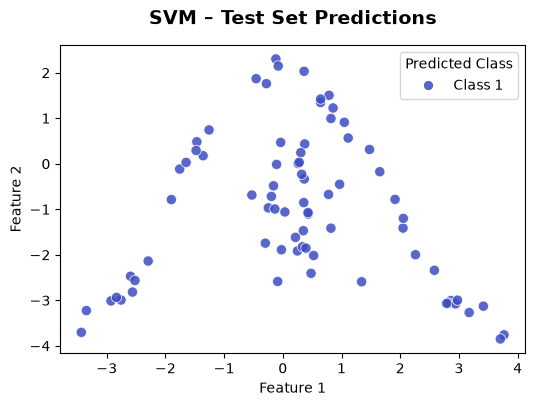

In [9]:
# visualize predictions
plt.figure(figsize=(6, 4))

scatter = plt.scatter(X_test[:, 0], X_test[:, 1],c=t_pred,cmap="coolwarm",s=55,alpha=0.85,edgecolors="white",linewidths=0.6)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("SVM – Test Set Predictions", fontsize=14, fontweight="bold", pad=15)

handles, _ = scatter.legend_elements()
classes = np.unique(t_pred)

plt.legend(handles=handles,labels=[f"Class {c}" for c in classes],title="Predicted Class",loc="best",frameon=True)
plt.show()

### Task 1.3

- Instead of using the linear kernel, use the Gaussian RBF kernel defined in Practical 3.
- Compare results on with both kernels with sklearn implementation (SVC)
- Visualize the predictions on the test set, the learned support vectors and the decision boundary for both kernels (Hint: Adapt the decision boundary plot from Practical 3).

In [10]:
def rbf_kernel(a, b):
    # ---------------- INSERT CODE ----------------------
    return np.exp(-np.sum((np.asarray(a) - np.asarray(b)) ** 2))
    # ---------------- END CODE -------------------------

In [11]:
# Fit SVM with rbf kernel and calculate the test accuracy

# Eigene SVM mit RBF-Kernel
alpha_rbf = fit_svm(X_train, t_train, rbf_kernel, C=1.0)

lagr_mult_rbf, svs_rbf, sv_labels_rbf, intercept_rbf = extract_parameters(X_train, t_train, rbf_kernel, alpha_rbf, C=1.0)

# Scikit-learn
svc_linear = SVC(kernel="linear", C=1.0)
svc_rbf = SVC(kernel="rbf", gamma=1.0, C=1.0)

svc_linear.fit(X_train, t_train)
svc_rbf.fit(X_train, t_train)

     pcost       dcost       gap    pres   dres
 0: -7.7018e+00 -2.6272e+02  1e+03  2e+00  7e-16
 1: -2.6542e+00 -1.1766e+02  1e+02  2e-15  8e-16
 2: -8.3809e+00 -2.1823e+01  1e+01  7e-16  8e-16
 3: -9.9541e+00 -1.4530e+01  5e+00  1e-15  5e-16
 4: -1.0601e+01 -1.1741e+01  1e+00  1e-15  5e-16
 5: -1.0840e+01 -1.1127e+01  3e-01  2e-15  5e-16
 6: -1.0903e+01 -1.0986e+01  8e-02  2e-15  5e-16
 7: -1.0927e+01 -1.0941e+01  1e-02  3e-15  6e-16
 8: -1.0932e+01 -1.0933e+01  2e-03  6e-16  5e-16
 9: -1.0932e+01 -1.0932e+01  3e-05  1e-15  5e-16
10: -1.0932e+01 -1.0932e+01  3e-07  3e-16  6e-16
Optimal solution found.


,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",1.0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [12]:
# Fit SVM using sklearn and calculate the test accuracy

# Linear Kernel
t_pred_linear = svc_linear.predict(X_test)
# RBF Kernel
t_pred_rbf = svc_rbf.predict(X_test)

# Eigene Vorhersagefunktionen
predict_linear = lambda X: svm_predict(X, linear_kernel, lagr_mult, svs, sv_labels, intercept)
predict_rbf = lambda X: svm_predict(X, rbf_kernel, lagr_mult_rbf, svs_rbf, sv_labels_rbf, intercept_rbf)

# Test Accuracy
print("               Own SVM    Scikit-learn")
print(f"Linear Kernel: {np.mean(predict_linear(X_test) == t_test):.2%}     {svc_linear.score(X_test, t_test):.2%}")
print(f"RBF Kernel:    {np.mean(predict_rbf(X_test) == t_test):.2%}    {svc_rbf.score(X_test, t_test):.2%}")

               Own SVM    Scikit-learn
Linear Kernel: 58.67%     58.67%
RBF Kernel:    100.00%    100.00%


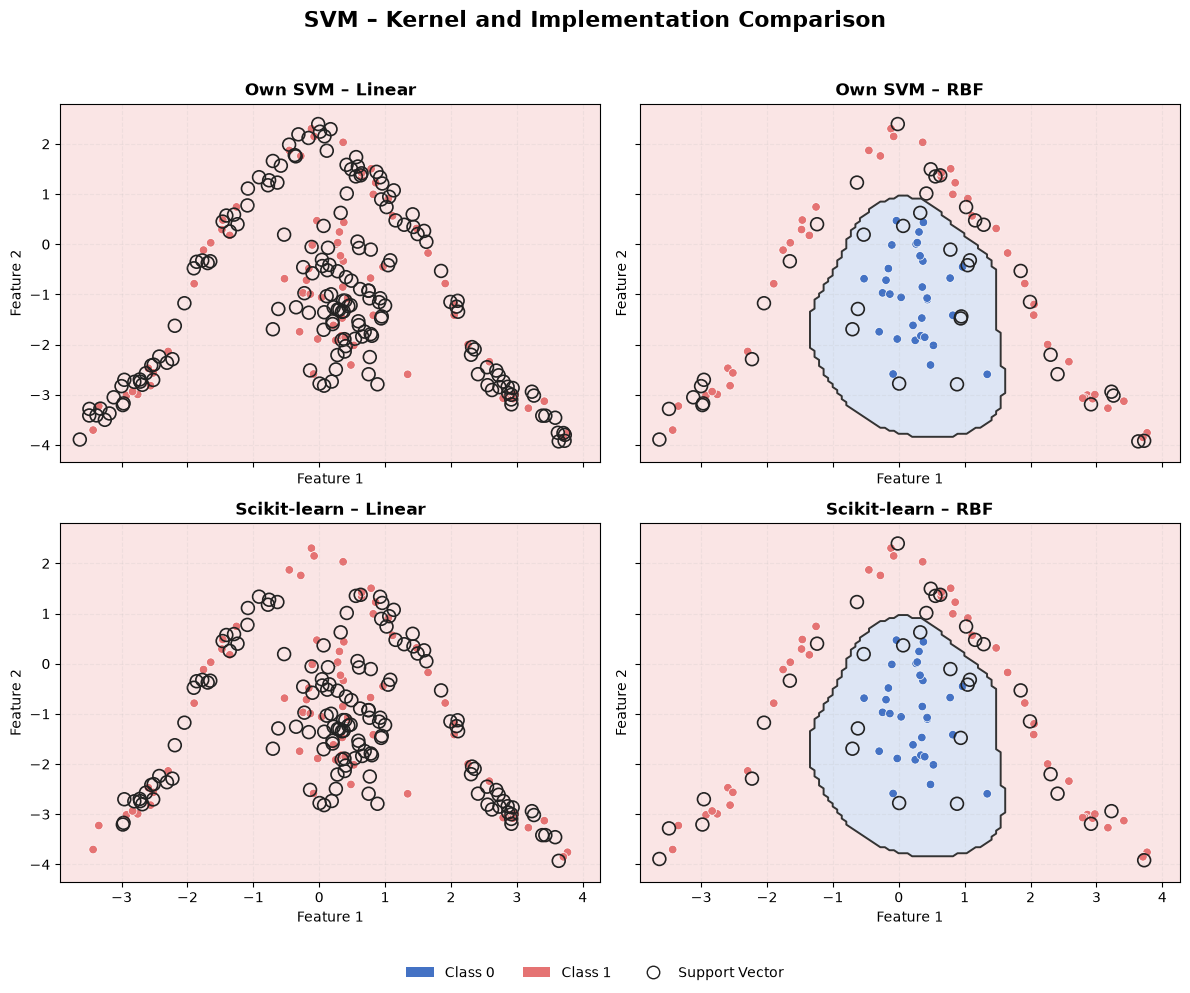

In [13]:
# Visualize
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def plot_decision_boundary(ax, predict_fn, support_vectors, title):
    x_min, x_max = X_test[:, 0].min() - 0.5, X_test[:, 0].max() + 0.5
    y_min, y_max = X_test[:, 1].min() - 0.5, X_test[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 120),
        np.linspace(y_min, y_max, 120)
    )

    grid = np.column_stack([xx.ravel(), yy.ravel()])
    grid_pred = np.asarray(predict_fn(grid)).ravel()

    # Klassen 0/1 und -1/+1 einheitlich behandeln
    grid_pred = (grid_pred > 0).astype(int).reshape(xx.shape)
    test_pred = (np.asarray(predict_fn(X_test)).ravel() > 0).astype(int)

    cmap = ListedColormap(["#4472C4", "#E57373"])

    ax.contourf(
        xx, yy, grid_pred,
        levels=[-0.5, 0.5, 1.5],
        cmap=cmap,
        alpha=0.18
    )

    if np.unique(grid_pred).size > 1:
        ax.contour(xx, yy, grid_pred, levels=[0.5],
                   colors="#333333", linewidths=1.4)

    ax.scatter(
        X_test[:, 0], X_test[:, 1],
        c=test_pred, cmap=cmap, vmin=0, vmax=1,
        s=38, edgecolors="white", linewidths=0.5
    )

    ax.scatter(
        support_vectors[:, 0], support_vectors[:, 1],
        s=85, facecolors="none", edgecolors="#222222",
        linewidths=1.2
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(alpha=0.15, linestyle="--")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)


# Ein gemeinsames Diagramm
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

models = [
    (predict_linear, svs, "Own SVM – Linear"),
    (predict_rbf, svs_rbf, "Own SVM – RBF"),
    (svc_linear.predict, svc_linear.support_vectors_, "Scikit-learn – Linear"),
    (svc_rbf.predict, svc_rbf.support_vectors_, "Scikit-learn – RBF")
]

for ax, (predict_fn, support_vectors, title) in zip(axes.flat, models):
    plot_decision_boundary(ax, predict_fn, support_vectors, title)

legend_elements = [
    Patch(facecolor="#4472C4", label="Class 0"),
    Patch(facecolor="#E57373", label="Class 1"),
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor="none", markeredgecolor="#222222",
           markersize=9, label="Support Vector")
]

fig.legend(handles=legend_elements, loc="lower center",
           ncol=3, frameon=False)

fig.suptitle("SVM – Kernel and Implementation Comparison",
             fontsize=16, fontweight="bold")

plt.tight_layout(rect=[0, 0.05, 1, 0.96])
plt.show()

In [14]:
print("Linear Kernel:")
print("Own SVM:", len(svs))
print("Scikit-learn:", len(svc_linear.support_vectors_))

print("\nRBF Kernel:")
print("Own SVM:", len(svs_rbf))
print("Scikit-learn:", len(svc_rbf.support_vectors_))

Linear Kernel:
Own SVM: 175
Scikit-learn: 144

RBF Kernel:
Own SVM: 41
Scikit-learn: 35


**Results:** Both implementations achieve identical test accuracies. The linear kernel reaches 58.67%, whereas the Gaussian RBF kernel achieves 100%. The RBF kernel successfully captures the nonlinear structure of the dataset. The decision boundaries are nearly identical, although the number of support vectors differs slightly between the implementations.

# Task 2: Decision Trees

Next, we will implement a simple decision tree classifier using the Wine dataset, one of the standard sklearn datasets. 

We will use the Gini impurity as a criterion for splitting. It is defined for a set of labels as
$$ G = \sum_{i=0}^C p(i) * (1- p(i)) $$

Given labels $l$ and split $l_a$ and $l_b$, the weighted removed impurity can be computed by $G(l) - \frac{|l_a|}{|l|}G(l_a) - \frac{|l_b|}{|l|}G(l_b)$.

Here is a simple explanation of the Gini impurity that you may find useful: https://victorzhou.com/blog/gini-impurity/


### Task 2.1

1. Plot the distribution of the first feature of for each class of the wine dataset.
2. Implement a function `gini_impurity(t)` that computes the Gini impurity for an array of labels `t`.
3. Calculate the removed Gini impurity for a split after 50 samples, i.e. between `t[:50]` and `t[50:]`.

In [15]:
# Load Wine dataset and split into train+test set

X, t = load_wine(return_X_y=True)
X_train, X_test, t_train, t_test = split_data(X, t)

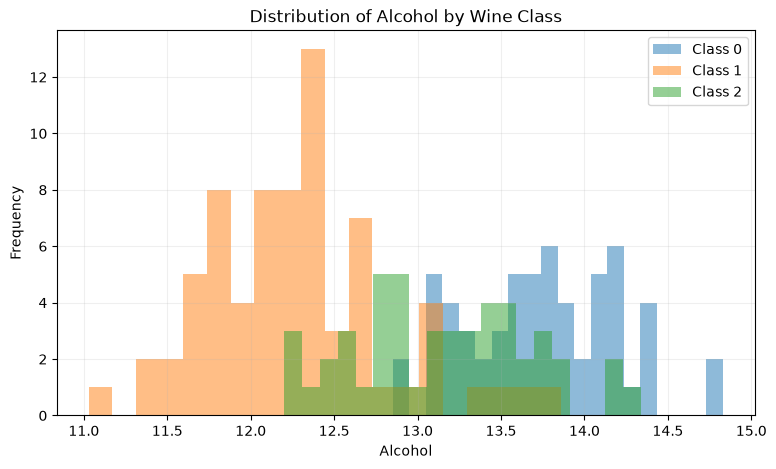

In [16]:
# Plot distribution
plt.figure(figsize=(9, 5))

for c in np.unique(t):
    plt.hist(X[t == c, 0], bins=20, alpha=0.5, label=f"Class {c}")

plt.xlabel("Alcohol")
plt.ylabel("Frequency")
plt.title("Distribution of Alcohol by Wine Class")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [17]:
# Compute Gini impurity
def gini_impurity(t):
    if len(t) == 0:
        return 0.0

    _, counts = np.unique(t, return_counts=True)
    probabilities = counts / len(t)

    return np.sum(probabilities * (1 - probabilities))

In [18]:
print(f'Gini impurity: {gini_impurity(t):.3f}')

Gini impurity: 0.658


In [19]:
print(f'Removed Gini impurity: {gini_impurity(t) - 50/len(t)*gini_impurity(t[:50]) - (len(t)-50)/len(t)*gini_impurity(t[50:])}')

Removed Gini impurity: 0.2651426982072971


### Task 2.2
For each of the first 12 features, compute the remove Gini impurity for every possible split. Visualize the removed Gini impurity per feature across all splits. Which is the optimal split?

In [20]:
def calculate_removed_gini(X, t, feature):
    thresholds = np.unique(X[:, feature])[:-1]
    gini_values = []

    for val in thresholds:
        mask = X[:, feature] <= val

        removed_gini = (
            gini_impurity(t)
            - np.sum(mask) / len(t) * gini_impurity(t[mask])
            - np.sum(~mask) / len(t) * gini_impurity(t[~mask])
        )

        gini_values.append(removed_gini)

    return thresholds, np.array(gini_values)  

In [21]:
results = []

for i in range(12):
    thresholds, gini_values = calculate_removed_gini(X, t, i)

    results.append({"feature": i, "thresholds": thresholds, "gini_values": gini_values})

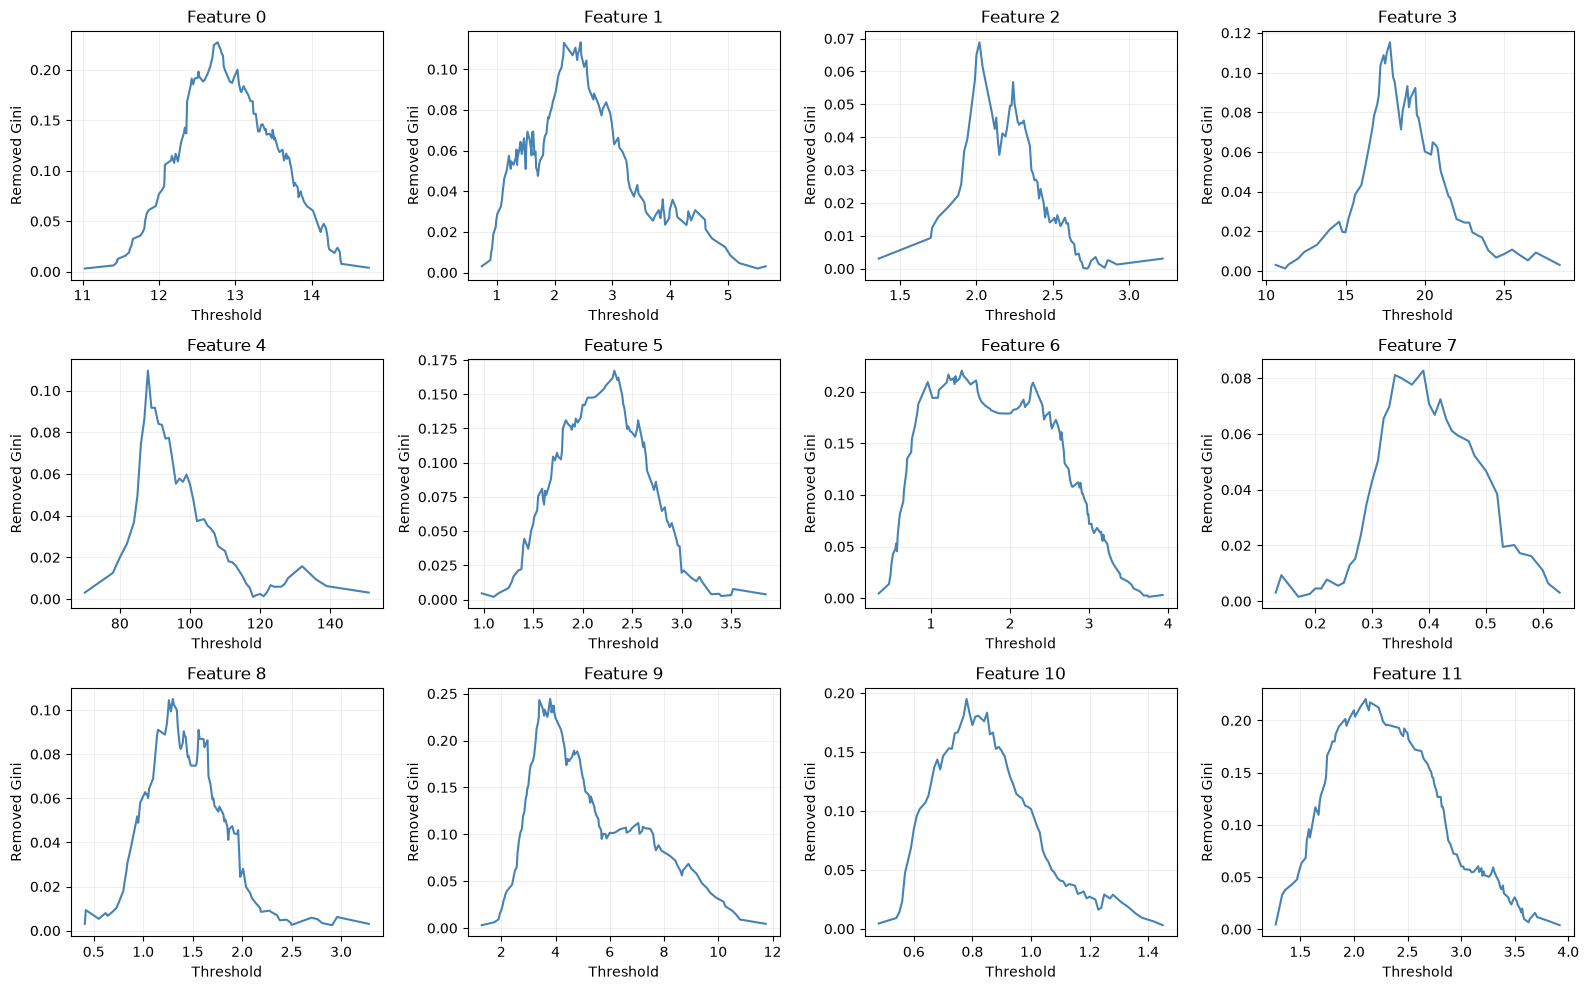

In [22]:
# Plotting
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for i, ax in enumerate(axes.flat):
    thresholds = results[i]["thresholds"]
    gini_values = results[i]["gini_values"]

    ax.plot(thresholds, gini_values, color="steelblue")

    ax.set_title(f"Feature {i}")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Removed Gini")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [23]:
best_feature = np.argmax([np.max(result["gini_values"]) for result in results])
best_idx = np.argmax(results[best_feature]["gini_values"])

print(f"Best feature: {best_feature}")
print(f"Best threshold: {results[best_feature]['thresholds'][best_idx]:.4f}")
print(f"Maximum removed Gini: {results[best_feature]['gini_values'][best_idx]:.4f}")

Best feature: 9
Best threshold: 3.8000
Maximum removed Gini: 0.2443


### Task 2.3

1. Implement a function `build_tree(X, t, depth)` which recursively builds a tree. Use the classes `Node` and `Leaf` as a data structure to build your tree.
2. Implement a function `predict_tree(tree, x)` which makes a prediction for sample `x`. Obtain scores for the `wine` dataset and compare to `sklearn.tree.DecisionTree`.
3. Switch back to the synthetic 2d dataset from the beginning (kernel methods). Compute scores and visualize the decisions in a 2d grid.

In [24]:
class Node:
    def __init__(self, left, right, n_feat, threshold):
        self.left = left
        self.right = right
        self.n_feat = n_feat
        self.threshold = threshold


class Leaf:
    def __init__(self, label):
        self.label = label

In [25]:
# Implement recursive tree function

def build_tree(X, t, depth, max_depth=3, n_labels=2):
    
    # ---------------- INSERT CODE ----------------------

    # Abbruchbedingung
    if depth >= max_depth or len(np.unique(t)) < n_labels:
        labels, counts = np.unique(t, return_counts=True)
        return Leaf(labels[np.argmax(counts)])

    # Besten Split suchen
    best_gini = 0
    best_feature = None
    best_threshold = None

    for i in range(X.shape[1]):
        for val in np.unique(X[:, i])[:-1]:

            mask = X[:, i] <= val

            removed_gini = (
                gini_impurity(t)
                - np.sum(mask) / len(t) * gini_impurity(t[mask])
                - np.sum(~mask) / len(t) * gini_impurity(t[~mask])
            )

            if removed_gini > best_gini:
                best_gini = removed_gini
                best_feature = i
                best_threshold = val

    # Kein sinnvoller Split gefunden
    if best_feature is None:
        labels, counts = np.unique(t, return_counts=True)
        return Leaf(labels[np.argmax(counts)])

    # Daten aufteilen
    mask = X[:, best_feature] <= best_threshold

    X_left, t_left = X[mask], t[mask]
    X_right, t_right = X[~mask], t[~mask]

    # Rekursion
    left = build_tree(X_left, t_left, depth + 1, max_depth, n_labels)
    right = build_tree(X_right, t_right, depth + 1, max_depth, n_labels)

    return Node(left, right, best_feature, best_threshold)

    # ---------------- END CODE -------------------------

    
def predict_tree(node, x):
    
    # ---------------- INSERT CODE ----------------------

    if isinstance(node, Leaf):
        return node.label

    if x[node.n_feat] <= node.threshold:
        return predict_tree(node.left, x)
    else:
        return predict_tree(node.right, x)

    # ---------------- END CODE -------------------------

In [26]:
# Build tree
tree = build_tree(X_train, t_train, 0, max_depth=3, n_labels=3)

In [27]:
# Calculate training and test scores
t_train_pred = np.array([predict_tree(tree, x) for x in X_train])
t_test_pred = np.array([predict_tree(tree, x) for x in X_test])

print("Own Decision Tree:")
print(f"Training Accuracy: {np.mean(t_train_pred == t_train):.2%}")
print(f"Test Accuracy:     {np.mean(t_test_pred == t_test):.2%}")

Own Decision Tree:
Training Accuracy: 96.00%
Test Accuracy:     84.91%


In [28]:
# Calculate test score using sklearn
clf = DecisionTreeClassifier(max_depth=3, criterion="gini", random_state=42)
clf.fit(X_train, t_train)

print("sklearn Decision Tree:")
print(f"Training Accuracy: {clf.score(X_train, t_train):.2%}")
print(f"Test Accuracy:     {clf.score(X_test, t_test):.2%}")

sklearn Decision Tree:
Training Accuracy: 98.40%
Test Accuracy:     88.68%


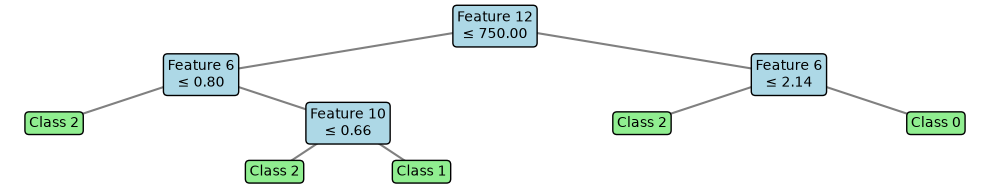

In [29]:
def plot_tree(tree, figsize=(10, 2)):
    fig, ax = plt.subplots(figsize=figsize)

    def draw_node(node, x, y, dx):
        if isinstance(node, Leaf):
            ax.text(
                x, y, f"Class {node.label}",
                ha="center", va="center",
                bbox=dict(boxstyle="round", facecolor="lightgreen")
            )
            return

        ax.text(
            x, y,
            f"Feature {node.n_feat}\n≤ {node.threshold:.2f}",
            ha="center", va="center",
            bbox=dict(boxstyle="round", facecolor="lightblue")
        )

        # Positionen der Kinder
        left_x = x - dx
        right_x = x + dx
        child_y = y - 1

        # Verbindungslinien
        ax.plot([x, left_x], [y, child_y], color="gray")
        ax.plot([x, right_x], [y, child_y], color="gray")

        # Rekursive Aufrufe
        draw_node(node.left, left_x, child_y, dx / 2)
        draw_node(node.right, right_x, child_y, dx / 2)

    draw_node(tree, x=0, y=0, dx=4)

    ax.axis("off")
    plt.tight_layout()
    plt.show()

plot_tree(tree)

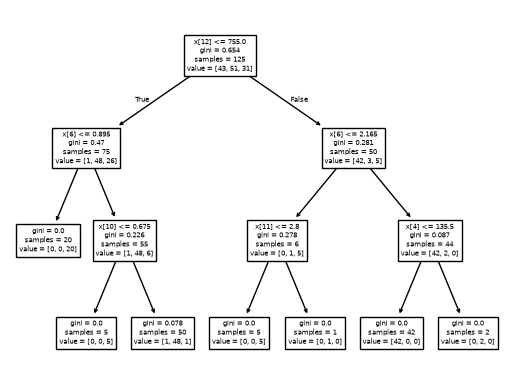

In [30]:
sklearn.tree.plot_tree(clf)
plt.show()

In [31]:
# Calculate test score for synthetic 2D dataset
X_2d, t_2d = np.load('data/nonlin_2d_data.npy')[:,:2], np.load('data/nonlin_2d_data.npy')[:, 2]
X_train_2d, X_test_2d, t_train_2d, t_test_2d = split_data(X_2d, t_2d, seed=1)

# Eigenen Decision Tree trainieren
tree_2d = build_tree(X_train_2d, t_train_2d, depth=0)

# Vorhersagen auf den Testdaten
t_pred_2d = np.array([predict_tree(tree_2d, x) for x in X_test_2d])

# Test Accuracy
test_score = np.mean(t_pred_2d == t_test_2d)

print(f"Decision Tree Test Accuracy: {test_score:.2%}")

Decision Tree Test Accuracy: 98.67%


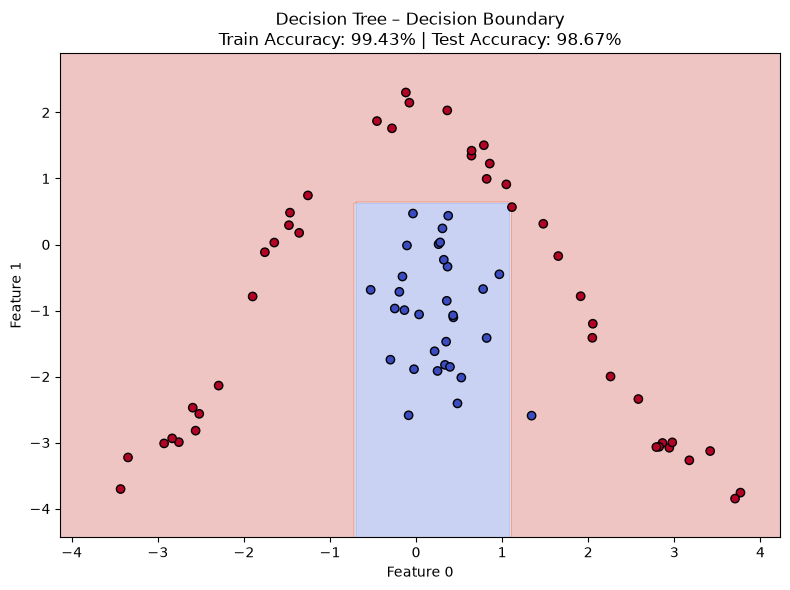

In [32]:
# Visualize

# Training und Test Accuracy berechnen
train_pred = np.array([predict_tree(tree_2d, x) for x in X_train_2d])
test_pred = np.array([predict_tree(tree_2d, x) for x in X_test_2d])

train_accuracy = np.mean(train_pred == t_train_2d)
test_accuracy = np.mean(test_pred == t_test_2d)

# Gitter erstellen
x_min, x_max = X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5
y_min, y_max = X_train_2d[:, 1].min() - 0.5, X_train_2d[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Gitterpunkte klassifizieren
grid = np.c_[xx.ravel(), yy.ravel()]

Z = np.array([predict_tree(tree_2d, x) for x in grid])
Z = Z.reshape(xx.shape)

# Visualisierung
plt.figure(figsize=(8, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")

plt.scatter(
    X_test_2d[:, 0],
    X_test_2d[:, 1],
    c=t_test_2d,
    cmap="coolwarm",
    edgecolors="black"
)

plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.title(
    f"Decision Tree – Decision Boundary\n"
    f"Train Accuracy: {train_accuracy:.2%} | Test Accuracy: {test_accuracy:.2%}"
)

plt.tight_layout()
plt.show()